# Financial Sentiment Classification with NLP
### Benchmarking Traditional and Deep Learning Models on the Financial PhraseBank dataset

## Project Summary

This project examines financial sentiment classification by building and evaluating traditional and deep learning natural language processing (NLP) models using the **Financial PhraseBank dataset**. The goal is to classify financial news sentences into **positive**, **negative** or **neutral** sentiments, this is critical for applications in market analysis, risk assessment and automated trading signals.  

Four models are explored: 
- Logistic Regression and Naive Bayes as traditional models,
- Convolutional Neural Network (CNN) and Bidirectional Long Short-Term Memory (Bi-LSTM) as deep learning models.  

The full pipeline:
1. Data loading and preprocessing
2. Exploratory Data Analysis (EDA) 
3. Text preprocessing (cleaning, tokenisation, lemmatisation)
4. Feature engineering (TF-IDF for traditional models, Keras for deep models)
5. Class imbalance handling (SMOTE for traditional, `class_weight` for deep)
6. Hyperparameter tuning (GridSearchCV and KerasTuner Hyperband)
7. Evaluation with accuracy and macro averaged F1 score
8. Model comparison and discussion

## Setup & Data Loading

Importing the necessary libraries then load the dataset `Sentences_75Agree.txt` into a pandas DataFrame for inspection.

In [1]:
import warnings
warnings.filterwarnings("ignore")

# Import libraries
import os
import re
import string
import nltk
import keras
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
import keras_tuner as kt
from keras import layers, models
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from transformers import BertTokenizer, BertForSequenceClassification
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from tensorflow.keras import models, layers
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from sklearn.utils import class_weight
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

E0000 00:00:1793785831.769445 3256470 instrument.cc:563] Metric with name 'grpc.resource_quota.calls_dropped' registered more than once. Ignoring later registration.
E0000 00:00:1793785831.769516 3256470 instrument.cc:563] Metric with name 'grpc.resource_quota.calls_rejected' registered more than once. Ignoring later registration.
E0000 00:00:1793785831.769517 3256470 instrument.cc:563] Metric with name 'grpc.resource_quota.connections_dropped' registered more than once. Ignoring later registration.
E0000 00:00:1793785831.769519 3256470 instrument.cc:563] Metric with name 'grpc.resource_quota.instantaneous_memory_pressure' registered more than once. Ignoring later registration.
E0000 00:00:1793785831.769519 3256470 instrument.cc:563] Metric with name 'grpc.resource_quota.memory_pressure_control_value' registered more than once. Ignoring later registration.
[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be u

Now that the libraries have been imported, a function is defined to load and inspect the dataset.

In [2]:
# Define a function to load and inspect the data  
def load_and_inspect_data(data_file):
    """
    This functions loads sentence data from a dataset file, assigns column names and performs an initial inspection.

    Argument:
        data_file (string): The path to the dataset file or the file name.

    Output:
        pandas.DataFrame: The loaded and inspected dataset.
    """
    # Load the dataset using '@' as a separator and latin-1 encoding for broader compatibility.
    df = pd.read_csv(data_file, sep='@', names=['sentence', 'sentiment'], encoding='latin-1')
        
    print("Dataset loaded successfully.\n")
    
    # Display the first 5 rows to verify the structure
    print("First 5 rows of the dataset:")
    print(df.head())
    print("")

    # Display Dataset info
    print("Dataset Info:")
    df.info()
    print("")
    
    # Display the dimensions of the DataFrame
    print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
    
    return df

In [3]:
# Execute the function
data_file = 'data/FinancialPhraseBank-v1.0/Sentences_75Agree.txt'
df = load_and_inspect_data(data_file)

Dataset loaded successfully.

First 5 rows of the dataset:
                                            sentence sentiment
0  According to Gran , the company has no plans t...   neutral
1  With the new production plant the company woul...  positive
2  For the last quarter of 2010 , Componenta 's n...  positive
3  In the third quarter of 2010 , net sales incre...  positive
4  Operating profit rose to EUR 13.1 mn from EUR ...  positive

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3453 entries, 0 to 3452
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   sentence   3453 non-null   object
 1   sentiment  3453 non-null   object
dtypes: object(2)
memory usage: 54.1+ KB

Dataset Shape: 3453 rows, 2 columns


## Exploratory Data Analysis and Preprocessing.

#### Class Distribution and Baseline Analysis

The distribution of the sentiment classes is analysed to identify any potential imbalance that can lead to a biased model. This analysis also establishes a majority class baseline, which is the minimum performance any useful model should exceed.

In [4]:
# Check for null values
print("Checking for null values:")
print(df.isnull().sum())

# Display the class distribution
print("\nClass Distribution:")
class_counts = df['sentiment'].value_counts()
class_pcts = df["sentiment"].value_counts(normalize=True) * 100
summary = pd.DataFrame({"Count": class_counts,
                        "Percentage": class_pcts.map("{:.1f}%".format)})
print(summary)

# find the label of the majority class
majority_class = class_counts.idxmax()  
majority_baseline = class_pcts.max() 

print(f"\nThe majority class '{majority_class}' accounts for {class_counts.max()}/{class_counts.sum()} of the data.")
print(f"\nA majority class baseline classifier would achieve an accuracy of at least: {majority_baseline:.2f}%")

Checking for null values:
sentence     0
sentiment    0
dtype: int64

Class Distribution:
           Count Percentage
sentiment                  
neutral     2146      62.1%
positive     887      25.7%
negative     420      12.2%

The majority class 'neutral' accounts for 2146/3453 of the data.

A majority class baseline classifier would achieve an accuracy of at least: 62.15%


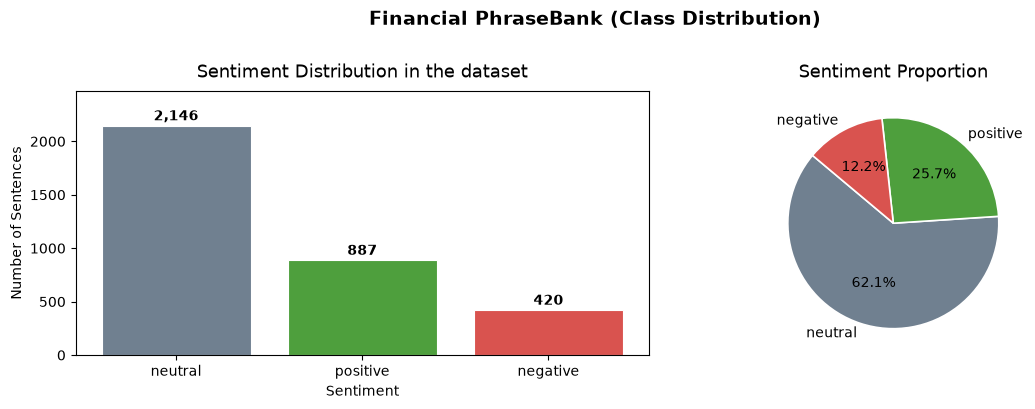


NB: The 'neutral' class dominates at ~62%. Without correction, models risk bias towards predicting neutral for everything.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

PALETTE = {"positive": "#4E9F3D", "negative": "#D9534F", "neutral": "#708090"}

# Left: raw distribution
bars = axes[0].bar(class_counts.index,
                   class_counts.values,
                   color=[PALETTE[s] for s in class_counts.index],
                   edgecolor="white", 
                   linewidth=0.8
                  )

for bar, val in zip(bars, class_counts.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 20,
        f"{val:,}",
        ha="center", va="bottom", fontsize=10, fontweight="bold",
    )
    
axes[0].set_title("Sentiment Distribution in the dataset", fontsize=13, pad=10)
axes[0].set_xlabel("Sentiment")
axes[0].set_ylabel("Number of Sentences")
axes[0].set_ylim(0, class_counts.max() * 1.15)

# Right: percentage pie chart
axes[1].pie(
    class_counts.values,
    labels=class_counts.index,
    autopct="%1.1f%%",
    colors=[PALETTE[s] for s in class_counts.index],
    startangle=140,
    wedgeprops={"edgecolor": "white", "linewidth": 1.2},
)
axes[1].set_title("Sentiment Proportion", fontsize=13, pad=10)

plt.suptitle("Financial PhraseBank (Class Distribution)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("outputs/Class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nNB: The 'neutral' class dominates at ~62%. Without correction, models risk bias towards predicting neutral for everything.")


#### Sentence Length Analysis

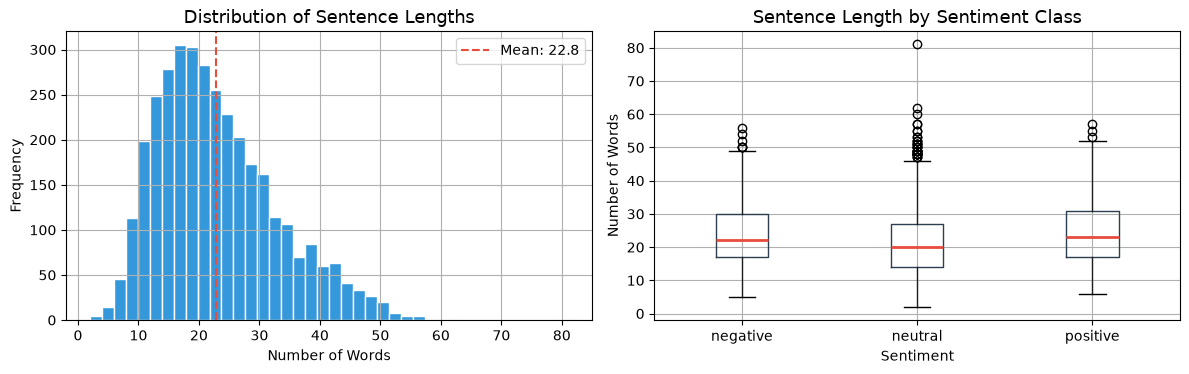


Sentence length statistics:
           mean   50%   max
sentiment                  
negative   24.5  22.0  56.0
neutral    21.5  20.0  81.0
positive   24.9  23.0  57.0


In [6]:
df["sentence_length"] = df["sentence"].apply(lambda x: len(x.split()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, label in zip(axes, ["sentence_length"]):
    pass

# Distribution of sentence lengths
df["sentence_length"].hist(bins=40, ax=axes[0], color="#3498db", edgecolor="white")
axes[0].set_title("Distribution of Sentence Lengths", fontsize=13)
axes[0].set_xlabel("Number of Words")
axes[0].set_ylabel("Frequency")
axes[0].axvline(df["sentence_length"].mean(), color="#e74c3c", linestyle="--", label=f"Mean: {df['sentence_length'].mean():.1f}")
axes[0].legend()

# Boxplot per class
df.boxplot(column="sentence_length", by="sentiment", ax=axes[1],
           boxprops=dict(color="#2c3e50"),
           medianprops=dict(color="#e74c3c", linewidth=2))
axes[1].set_title("Sentence Length by Sentiment Class", fontsize=13)
axes[1].set_xlabel("Sentiment")
axes[1].set_ylabel("Number of Words")
plt.suptitle("")

plt.tight_layout()
plt.savefig("outputs/Sentence_lengths.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nSentence length statistics:")
print(df.groupby("sentiment")["sentence_length"].describe()[["mean", "50%", "max"]].round(1))

All three sentiment classes share a similar average sentence length of roughly 22 - 25 words (median: 20 - 23 words). The distribution is unimodal and positively skewed, with most financial sentences falling between 10 and 30 words. The neutral class contains the longest sentence in the dataset (81 words), while positive and negative sentiments max around 56 - 57 words.

#### Text Preprocessing

The text will be standardised, converting it to lowercase, removing features like URLs and punctuations. A placeholder will be used to replace numbers, the sentences will be tokenised into words, removing common English stop words and performing lemmatization to reduce words to their base form. This entire process is processed using a reusable function `clean_text`.

In [7]:
# Download NLTK packages
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

In [8]:
# Define a function to clean the texts

def clean_text(text):
    """
    This function cleans text data, converting to lowercase, removing punctuations, URLs and replacing numbers with a token

    Argument:
        text: uncleaned text data

    Output:
        cleaned text in lowercase, without punctuations, URLs and numbers replaced with a <NUM> token
    """
    # Convert text to lowercase
    text = text.lower()
    # Remove URLs
    text = re.sub(r'http\S+', '', text)
    # Replace numbers with a <NUM> token
    text = re.sub(r'\d+(\.\d+)?', '<NUM>', text)
    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation.replace('<','').replace('>',''))) # Keep <> for the token
    
    # Tokenize the text, splitting them into words
    tokens = text.split()
    
    # Remove common English stop words
    tokens = [word for word in tokens if word not in stop_words]
    
    # Lemmatize tokens 
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    
    # Join tokens back into a single string
    return ' '.join(tokens)
    
# Apply the cleaning function to the 'sentence' column
df['cleaned_sentence'] = df['sentence'].apply(clean_text)

print("Preprocessing complete. A preview of the cleaned data:")
df.head()

Preprocessing complete. A preview of the cleaned data:


,sentence,sentiment,sentence_length,cleaned_sentence
0,"According to Gran , the company has no plans t...",neutral,25,according gran company plan move production ru...
1,With the new production plant the company woul...,positive,33,new production plant company would increase ca...
2,"For the last quarter of 2010 , Componenta 's n...",positive,39,last quarter <NUM> componenta net sale doubled...
3,"In the third quarter of 2010 , net sales incre...",positive,29,third quarter <NUM> net sale increased <NUM> e...
4,Operating profit rose to EUR 13.1 mn from EUR ...,positive,24,operating profit rose eur <NUM> mn eur <NUM> m...


#### Word Cloud Visualisation

Word clouds for each sentiment class using the preprocessed text will be generated. This helps to visualise the most frequent and potentially important words associated with positive, neutral and negative financial news.

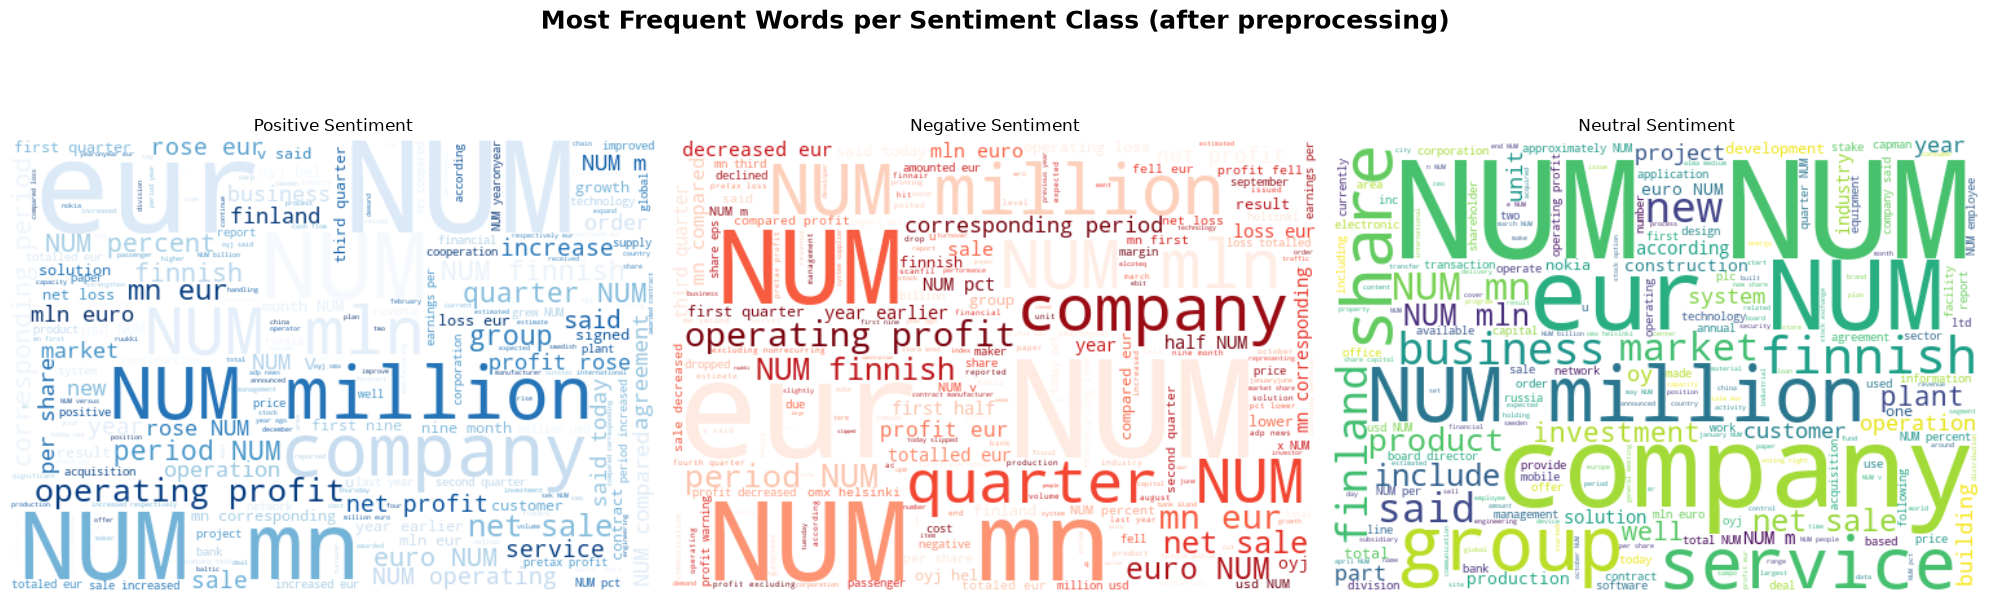

In [9]:
from wordcloud import WordCloud

# Create a figure to hold the word clouds
plt.figure(figsize=(20, 7))

# Word cloud for positive sentiment
positive_text = ' '.join(df[df['sentiment'] == 'positive']['cleaned_sentence'])
wordcloud_positive = WordCloud(width=500, height=350, background_color='white', colormap='Blues').generate(positive_text)

plt.subplot(1, 3, 1) # set subplot position
plt.imshow(wordcloud_positive, interpolation='bilinear') # plot subplot
plt.title('Positive Sentiment') # set subplot title
plt.axis('off') # remove subplot axis

# Word cloud for negative sentiment
negative_text = ' '.join(df[df['sentiment'] == 'negative']['cleaned_sentence'])
wordcloud_negative = WordCloud(width=500, height=350, background_color='white', colormap='Reds').generate(negative_text)

plt.subplot(1, 3, 2) # set subplot position
plt.imshow(wordcloud_negative, interpolation='bilinear') # plot subplot
plt.title('Negative Sentiment') # set subplot title
plt.axis('off') # remove subplot axis

# Word cloud for neutral sentiment
neutral_text = ' '.join(df[df['sentiment'] == 'neutral']['cleaned_sentence'])
wordcloud_neutral = WordCloud(width=500, height=350, background_color='white').generate(neutral_text)

plt.subplot(1, 3, 3) # set subplot position
plt.imshow(wordcloud_neutral, interpolation='bilinear') # plot subplot
plt.title('Neutral Sentiment') # set subplot title
plt.axis('off') # remove subplot axis

plt.suptitle("Most Frequent Words per Sentiment Class (after preprocessing)", fontsize=18, fontweight="bold")
plt.tight_layout()
plt.savefig('outputs/sentiment_wordclouds.png', dpi=150, bbox_inches='tight')
plt.show() # show the plot

#### Feature Engineering and Data Splitting

With the text cleaned, the data will be split into training and testing sets. The textual data will be converted into a numerical format that the machine learning models can understand using the Term Frequency-Inverse Document Frequency (TF-IDF) vectorisation technique.

In [10]:
# Split the data into features (X) and target (y)
X = df['cleaned_sentence']
y = df['sentiment']

# Split the data into training (80%) and testing sets (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Initialise and fit the TF-IDF Vectorizer on the training data
vectorizer = TfidfVectorizer(max_features=5000) # Limit features to the top 5000 for efficiency
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test) # Only transform the test data

print(f"Training data shape (TF-IDF): {X_train_tfidf.shape}")
print(f"Test data shape (TF-IDF): {X_test_tfidf.shape}")

Training data shape (TF-IDF): (2762, 5000)
Test data shape (TF-IDF): (691, 5000)


`max_features():` controls the number of unique words/tokens that will be used as features. After analysing the text in the training data, the vectorizer builds a vocabulary of all unique words. `max_features=5000` tells the vectorizer to only consider the top 5,000 most frequently occurring words and to discard all less occurring words. Each of these 5,000 words becomes a column in the TF-IDF matrix.

#### Handling Class Imbalance with Synthetic Minority Oversampling Technique (SMOTE)

As has been identified, the sentiment data is imbalanced. SMOTE will be applied to the training data only, to correct this. SMOTE creates new synthetic samples for the minority classes (positive and negative) to balance the class distribution, which should help prevent the model from being biased towards the majority neutral class.

In [11]:
# Handling class imbalance using SMOTE
from imblearn.over_sampling import SMOTE

print("Class distribution before SMOTE:")
print(y_train.value_counts())

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_tfidf, y_train)

print("\nClass distribution after SMOTE:")
print(y_train_smote.value_counts())

Class distribution before SMOTE:
sentiment
neutral     1717
positive     709
negative     336
Name: count, dtype: int64

Class distribution after SMOTE:
sentiment
neutral     1717
negative    1717
positive    1717
Name: count, dtype: int64


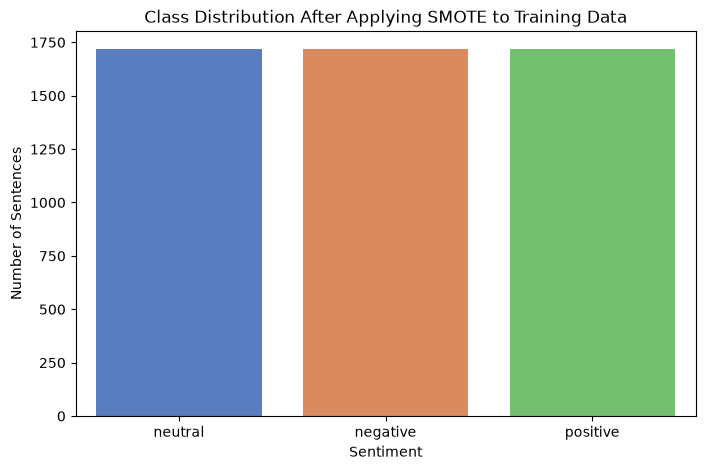

In [12]:
# Plot to confirm the balanced class distribution after SMOTE
plt.figure(figsize=(8, 5)) # set the plot size
sns.countplot(
    x=y_train_smote,
    hue=y_train_smote, # Assign hue to the data categories
    palette='muted'
)
plt.legend([], [], frameon=False) # Hides the redundant legend generated by hue
plt.title('Class Distribution After Applying SMOTE to Training Data') # set plot title
plt.xlabel('Sentiment') # set the label of the x axis
plt.ylabel('Number of Sentences') # set the label of the y axis
plt.savefig('outputs/label_distribution_smote.png') # save the plot
plt.show() # show the plot

## Traditional Machine Learning Models

Two traditional machine learning models will be implemented: **Logistic Regression** and **Multinomial Naive Bayes**.  

For both models, `GridSearchCV` will be used to perform 5 fold cross validation and find the optimal hyperparameters. The models are trained on the SMOTE-balanced data to ensure they learn from all classes effectively.

The `train_and_evaluate_model` function will be used to ensure that the code is clean and reusable. The results will be stored in the `model_results` dictionary for a final comparison.

In [13]:
# Initialise a dictionary to store all model results for comparison
model_results = {}

In [14]:
def plot_confusion_matrix(cm, classes, title):
    """This function prints and plots a confusion matrix.
    
    Arguments:
        cm: confusion matrix
        classes: name of the ML model 
        title (string): text used to generate the file name for the plot
    
    Returns:
        A confusion matrix
    """
    plt.figure(figsize=(6, 5)) # set plot size
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes) # plot confusion matrix
    plt.title(title) # set plot title
    plt.ylabel('True label') # set y label
    plt.xlabel('Predicted label') # set x label
    filename = f"outputs/{title.replace(' ', '_')}.png" # Create a filename from the title
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"Confusion matrix plot saved as '{filename}'")
    plt.show() # show plot

In [15]:
def train_and_evaluate_model(model, params, X_train, y_train, X_test, y_test):
    """
    This function trains and tunes a model using GridSearchCV, evaluates it, stores the results and plots its confusion matrix.

    Arguments:
        model: The ML model to be trained.
        params: Dictionary of hyperparameters for GridSearchCV.
        X_train, y_train: Training features and labels.
        X_test, y_test: Test features and labels.

    Returns:
        best_model: The trained model with the best parameters found by GridSearchCV.
    """
    # Get model name for display and result tracking
    model_name = model.__class__.__name__
    print(f"Training and Tuning {model_name} ")

    # Set up grid search with cross-validation and macro-averaged F1 score
    grid_search = GridSearchCV(
        model, 
        params, 
        cv=5, # 5-fold cross-validation
        scoring='f1_macro', # scoring metric
        n_jobs=-1, 
        verbose=1) # show progress
    
    # Perform grid search and fit model to training data
    grid_search.fit(X_train, y_train)

    # Display best hyperparameters and corresponding cross-validation score
    print(f"\nBest parameters for {model_name}: {grid_search.best_params_}")
    print(f"Best cross-validation F1-score (macro): {grid_search.best_score_:.4f}\n")

    # Extract the best model found by grid search
    best_model = grid_search.best_estimator_

    # Make predictions on the test set
    y_pred = best_model.predict(X_test)
    
    # Display Classification Report
    print(f"Classification Report for {model_name} on Test Set:")
    print(classification_report(y_test, y_pred, digits=4))
    
    # Save results into a dictionary for later comparison
    report = classification_report(y_test, y_pred, output_dict=True)
    model_results[model_name] = {
        'f1_score_macro': report['macro avg']['f1-score'],
        'accuracy': report['accuracy'],
        'best_params': grid_search.best_params_}
    
    # Generate and plot confusion matrix for evaluation
    cm = confusion_matrix(y_test, y_pred)
    plot_confusion_matrix(cm, classes=best_model.classes_, title=f'{model_name} Confusion Matrix')

    # Return the tuned best model for further use
    return best_model

### Logistic Regression

Training and Tuning LogisticRegression 
Fitting 5 folds for each of 8 candidates, totalling 40 fits

Best parameters for LogisticRegression: {'C': 100, 'solver': 'saga'}
Best cross-validation F1-score (macro): 0.9434

Classification Report for LogisticRegression on Test Set:
              precision    recall  f1-score   support

    negative     0.6883    0.6310    0.6584        84
     neutral     0.8744    0.9091    0.8914       429
    positive     0.7560    0.7135    0.7341       178

    accuracy                         0.8249       691
   macro avg     0.7729    0.7512    0.7613       691
weighted avg     0.8213    0.8249    0.8226       691

Confusion matrix plot saved as 'outputs/LogisticRegression_Confusion_Matrix.png'


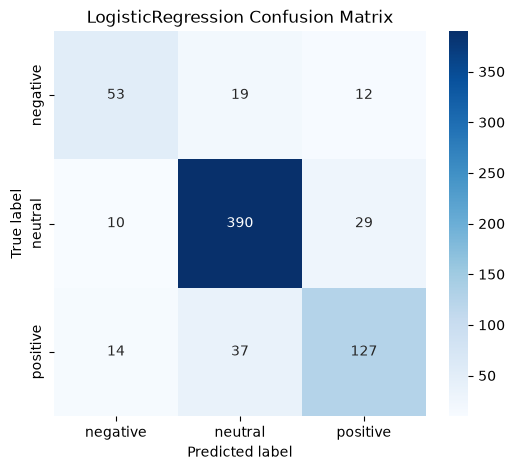

In [16]:
# Define the Logistic Regression model and its parameter grid
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_params = {'C': [0.1, 1, 10, 100],
             'solver': ['liblinear', 'saga']}

# Use the train_and_evaluate_model function to train, tune and evaluate the model
best_lr_model = train_and_evaluate_model(lr_model, lr_params, X_train_smote, y_train_smote, X_test_tfidf, y_test)

In [17]:
# Checking the model results dictionary earlier created
model_results 

{'LogisticRegression': {'f1_score_macro': 0.761305903613016,
  'accuracy': 0.8248914616497829,
  'best_params': {'C': 100, 'solver': 'saga'}}}

### Multinomial Naive Bayes

Training and Tuning MultinomialNB 
Fitting 5 folds for each of 6 candidates, totalling 30 fits

Best parameters for MultinomialNB: {'alpha': 0.01}
Best cross-validation F1-score (macro): 0.8947

Classification Report for MultinomialNB on Test Set:
              precision    recall  f1-score   support

    negative     0.5319    0.5952    0.5618        84
     neutral     0.8501    0.8462    0.8481       429
    positive     0.6412    0.6124    0.6264       178

    accuracy                         0.7554       691
   macro avg     0.6744    0.6846    0.6788       691
weighted avg     0.7576    0.7554    0.7562       691

Confusion matrix plot saved as 'outputs/MultinomialNB_Confusion_Matrix.png'


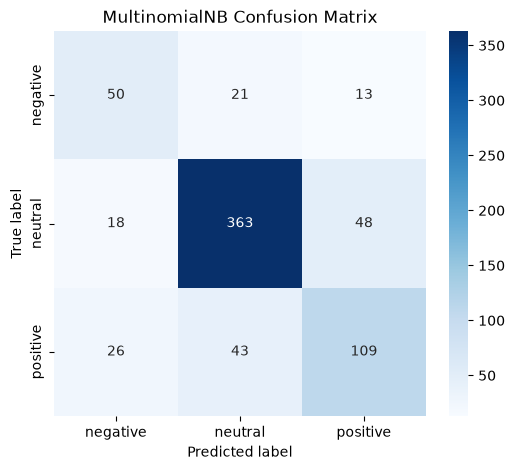

In [18]:
# Define the Naive Bayes model and its parameter grid
nb_model = MultinomialNB()
nb_params = {'alpha': [0.01, 0.1, 0.5, 1.0, 5.0, 10.0]}

# Train, tune and evaluate the model using the helper function
best_nb_model = train_and_evaluate_model(nb_model, nb_params, X_train_smote, y_train_smote, X_test_tfidf, y_test)

In [19]:
# Results check
model_results 

{'LogisticRegression': {'f1_score_macro': 0.761305903613016,
  'accuracy': 0.8248914616497829,
  'best_params': {'C': 100, 'solver': 'saga'}},
 'MultinomialNB': {'f1_score_macro': 0.6787884585132264,
  'accuracy': 0.7554269175108539,
  'best_params': {'alpha': 0.01}}}

## Deep Learning Models

Two deep learning models are implemented: a Convolutional Neural Network (CNN) and a BiLSTM model. The KerasTuner library will be used for hyperparameter tuning. This systematically searches for the best model architecture and training configurations. _EarlyStopping_ and _class_weight_ are respectively used to prevent overfitting and handle the imbalanced nature of the dataset.

**Evaluation:**
Each tuned model will be evaluated using the test data and visualisations will be generated:
1. Training History Plot: To visualise the learning curves (accuracy and loss) over epochs.
2. Confusion Matrix: To analyse the models' prediction accuracy.

The best results will be saved to the `model_results` dictionary for a final comparison with the traditional models.

**Data Preparation**

In [20]:
# Define hyperparameters
VOCAB_SIZE = 10000
EMBEDDING_DIM = 128
MAX_LEN = 100

X_train_cnn, X_val_cnn, y_train_cnn, y_val_cnn = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Initialise tokenizer
tokenizer = Tokenizer(
    num_words=VOCAB_SIZE,
    oov_token='<OOV>'
)

# Fit tokenizer only on the CNN training subset
tokenizer.fit_on_texts(X_train_cnn.tolist())

# Convert text to sequences and pad
X_train_pad = pad_sequences(
    tokenizer.texts_to_sequences(X_train_cnn.tolist()),
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

X_val_pad = pad_sequences(
    tokenizer.texts_to_sequences(X_val_cnn.tolist()),
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

X_test_pad = pad_sequences(
    tokenizer.texts_to_sequences(X_test.tolist()),
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

# Encode sentiment labels
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train_cnn)
y_val_encoded = label_encoder.transform(y_val_cnn)
y_test_encoded = label_encoder.transform(y_test)

# Calculate class weights to handle data imbalance
class_weights_array = class_weight.compute_class_weight('balanced', classes=np.unique(y_train_encoded), y=y_train_encoded)
class_weight_dict = dict(enumerate(class_weights_array))
print(f"Class Weight Dictionary: {class_weight_dict}")

# Define EarlyStopping callback
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, mode='min', verbose=1)

# Display dataset sizes
print("CNN training samples:", len(X_train_pad))
print("CNN validation samples:", len(X_val_pad))
print("CNN test samples:", len(X_test_pad))

print("\nEncoded classes:", label_encoder.classes_)

Class Weight Dictionary: {0: np.float64(2.73729863692689), 1: np.float64(0.5362952172857489), 2: np.float64(1.2986478542034097)}
CNN training samples: 2209
CNN validation samples: 553
CNN test samples: 691

Encoded classes: ['negative' 'neutral' 'positive']


In [21]:
# Define function for plotting training history (accuracy and loss)

def plot_training_history(history, model_name):
    """
    This function plots and saves the training & validation accuracy & loss curves for a given model.

    Arguments:
        history (keras.callbacks.History): The history object returned by model.fit() containing training metrics.
        model_name (string): The name of the model (used in the plot titles and saved file name).

    Returns:
        - A plot of accuracy and loss over training epochs.
        - Saves the plot as a PNG file.
        - Displays the plot in the notebook after saving.
    """
    plt.figure(figsize=(12, 5))
    
    # Plot Accuracy  
    plt.subplot(1, 2, 1) # set plot position
    plt.plot(history.history['accuracy'], label='Training Accuracy') # plot training accuracy
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy', linestyle="--") # plot validation accuracy
    plt.title(f'{model_name} Accuracy') # set plot title
    plt.xlabel('Epoch') # set x label
    plt.ylabel('Accuracy') # set y label
    plt.legend() # set plot legend
    
    # Plot Loss  
    plt.subplot(1, 2, 2) # set plot position
    plt.plot(history.history['loss'], label='Training Loss') # plot training loss
    plt.plot(history.history['val_loss'], label='Validation Loss', linestyle="--") # plot validation loss
    plt.title(f'{model_name} Loss') # set plot title
    plt.xlabel('Epoch') # set x label
    plt.ylabel('Loss') # set y label
    plt.legend() # set plot legend
    
    # Adjust layout
    plt.tight_layout()
    
    # Save the plot 
    file_name = f"outputs/{model_name}_training_history.png"
    plt.savefig(file_name, dpi=300, bbox_inches='tight')
    
    # Show the plot
    plt.show()
    
    print(f" Training history plot saved as {file_name}")

### Convolutional Neural Network (CNN)
A function is defined to build the CNN model. The KerasTuner `hp` object is used to define the search space for key hyperparameters like filter count, learning rate and dropout rate.

In [22]:
def build_cnn_model(hp):
    """
    This function builds and compiles a tunable CNN model for text classification.

    Arguments:
        hp (kerastuner.HyperParameters): Object used by KerasTuner to suggest values for hyperparameters.

    Returns:
        model (tf.keras.Model): Compiled CNN model ready for training with the specified hyperparameters.
    """
    model = models.Sequential()

    # Embedding layer to convert integer word indices to dense vectors
    model.add(layers.Embedding(input_dim=VOCAB_SIZE,  # total unique words in vocabulary
                               output_dim=EMBEDDING_DIM,  # size of each word vector
                               input_length=MAX_LEN))  # length of input sequences

    # First Conv1D layer, tune number of filters between 64 & 128
    hp_filters_1 = hp.Int('filters_1', min_value=64, max_value=128, step=32)
    model.add(layers.Conv1D(filters=hp_filters_1, kernel_size=5, activation='relu'))
    model.add(layers.MaxPooling1D(pool_size=2))  

    # Second Conv1D layer, tune number of filters between 32 & 64
    hp_filters_2 = hp.Int('filters_2', min_value=32, max_value=64, step=32)
    model.add(layers.Conv1D(filters=hp_filters_2, kernel_size=3, activation='relu'))
    model.add(layers.GlobalMaxPooling1D())  

    # Fully connected dense layer, tune number of units between 32 & 128
    hp_dense_units = hp.Int('dense_units', min_value=32, max_value=128, step=32)
    model.add(layers.Dense(units=hp_dense_units, activation='relu'))

    # Dropout layer, tune dropout rate between 0.2 & 0.5
    hp_dropout = hp.Float('dropout', min_value=0.2, max_value=0.5, step=0.1)
    model.add(layers.Dropout(hp_dropout))

    # Output layer, 3 classes with softmax activation
    model.add(layers.Dense(3, activation='softmax'))

    # Tune learning rate for Adam optimizer
    hp_learning_rate = hp.Choice('learning_rate', values=[1e-3, 1e-4])

    # Compile the model
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=hp_learning_rate),
                  loss='sparse_categorical_crossentropy',  # for integer labels
                  metrics=['accuracy'])

    return model

In [23]:
# Create a Hyperband tuner for CNN model hyperparameter optimization
tuner_cnn = kt.Hyperband(build_cnn_model, # function that builds the CNN model
                         objective='val_accuracy', # metric to optimise
                         max_epochs=10, # maximum number of epochs per model
                         factor=3, # reduction factor for Hyperband 
                         directory='kerastuner', # where tuning logs and checkpoints are stored
                         project_name='cnn_tuning') # subfolder name for this tuning run

# Run the hyperparameter search
print("\n Starting CNN Hyperparameter Search ")
tuner_cnn.search(X_train_pad, # preprocessed/padded training data
                 y_train_encoded, # encoded labels
                 epochs=10, # number of epochs per trial
                 validation_split=0.2, # fraction of training data used for validation
                 callbacks=[early_stopping], # early stopping to prevent overfitting
                 class_weight=class_weight_dict) # handles class imbalance during training

# Get the best hyperparameters found by the tuner
best_hps_cnn = tuner_cnn.get_best_hyperparameters(num_trials=1)[0]

# Get the best model architecture and weights from the tuning process
best_cnn_model = tuner_cnn.get_best_models(num_models=1)[0]

print(f"""
--- CNN Tuning Complete ---
Optimal number of filters in Conv1: {best_hps_cnn.get('filters_1')}
Optimal number of filters in Conv2: {best_hps_cnn.get('filters_2')}
Optimal number of units in Dense layer: {best_hps_cnn.get('dense_units')}
Optimal dropout rate: {best_hps_cnn.get('dropout'):.2f}
Optimal learning rate: {best_hps_cnn.get('learning_rate')}
""")

Reloading Tuner from kerastuner/cnn_tuning/tuner0.json

 Starting CNN Hyperparameter Search 

--- CNN Tuning Complete ---
Optimal number of filters in Conv1: 128
Optimal number of filters in Conv2: 32
Optimal number of units in Dense layer: 96
Optimal dropout rate: 0.30
Optimal learning rate: 0.001



**Training and Evaluation**  
Now the best CNN model configuration is trained on the full training data to generate its learning history and evaluate its final performance on the test set.

Epoch 1/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5242 - loss: 1.4994 - val_accuracy: 0.6510 - val_loss: 0.8209
Epoch 2/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7868 - loss: 0.6642 - val_accuracy: 0.7071 - val_loss: 0.7211
Epoch 3/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9058 - loss: 0.3472 - val_accuracy: 0.7559 - val_loss: 0.6236
Epoch 4/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9629 - loss: 0.1577 - val_accuracy: 0.7902 - val_loss: 0.6601
Epoch 5/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9842 - loss: 0.0721 - val_accuracy: 0.7975 - val_loss: 0.7420
Epoch 6/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9869 - loss: 0.0534 - val_accuracy: 0.7993 - val_loss: 0.7529
Epoch 6: early stopping
Restoring model weights from the end of the best epoch: 3.


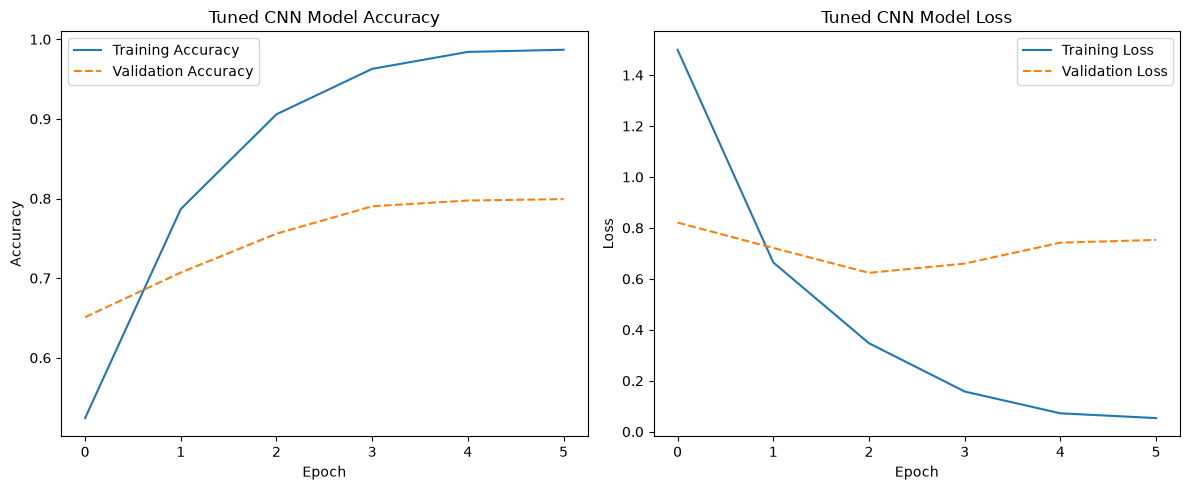

 Training history plot saved as outputs/Tuned CNN Model_training_history.png
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

 Tuned CNN Classification Report
              precision    recall  f1-score   support

    negative     0.5532    0.6190    0.5843        84
     neutral     0.8729    0.8322    0.8520       429
    positive     0.6489    0.6854    0.6667       178

    accuracy                         0.7685       691
   macro avg     0.6917    0.7122    0.7010       691
weighted avg     0.7763    0.7685    0.7717       691



In [24]:
# Train the best CNN model to get its history object for plotting
history_cnn = best_cnn_model.fit(
    X_train_pad, # preprocessed/padded training data
    y_train_encoded, # encoded labels
    epochs=20, # number of epochs  
    validation_data=(X_val_pad, y_val_encoded),
    class_weight=class_weight_dict, # handles class imbalance  
    callbacks=[early_stopping], # early stopping to prevent overfitting
    verbose=1)

# Training history visualisation
plot_training_history(history_cnn, "Tuned CNN Model")

# Final CNN evaluation
y_pred_probs_cnn = best_cnn_model.predict(X_test_pad)
y_pred_cnn = np.argmax(y_pred_probs_cnn, axis=1)

print("\n Tuned CNN Classification Report")
print(classification_report(y_test_encoded, y_pred_cnn, target_names=label_encoder.classes_, digits=4))

Confusion matrix plot saved as 'outputs/Tuned_CNN_Confusion_Matrix.png'


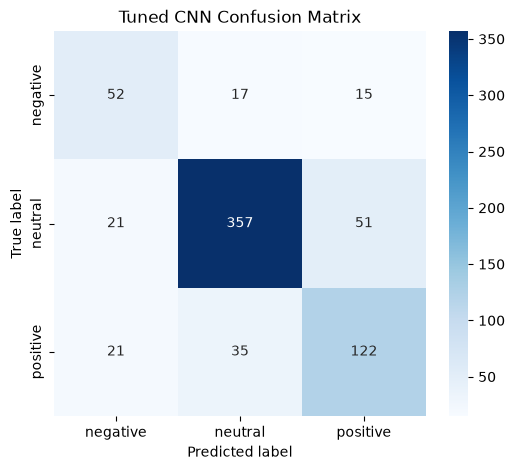


Tuned CNN results saved to results dictionary.


In [25]:
# Confusion Matrix visualisation
cm_cnn = confusion_matrix(y_test_encoded, y_pred_cnn)
plot_confusion_matrix(cm_cnn, classes=label_encoder.classes_, title='Tuned CNN Confusion Matrix')

# Save the model's results
report_cnn = classification_report(y_test_encoded, y_pred_cnn, output_dict=True)
model_results['Tuned CNN'] = {
    'f1_score_macro': report_cnn['macro avg']['f1-score'],
    'accuracy': report_cnn['accuracy'],
    'best_params': best_hps_cnn.values}

print("\nTuned CNN results saved to results dictionary.")

In [26]:
# Checking the model results dictionary earlier created
model_results 

{'LogisticRegression': {'f1_score_macro': 0.761305903613016,
  'accuracy': 0.8248914616497829,
  'best_params': {'C': 100, 'solver': 'saga'}},
 'MultinomialNB': {'f1_score_macro': 0.6787884585132264,
  'accuracy': 0.7554269175108539,
  'best_params': {'alpha': 0.01}},
 'Tuned CNN': {'f1_score_macro': 0.7009883230687177,
  'accuracy': 0.768451519536903,
  'best_params': {'filters_1': 128,
   'filters_2': 32,
   'dense_units': 96,
   'dropout': 0.30000000000000004,
   'learning_rate': 0.001,
   'tuner/epochs': 10,
   'tuner/initial_epoch': 4,
   'tuner/bracket': 1,
   'tuner/round': 1,
   'tuner/trial_id': '0019'}}}

The tuned CNN model exhibits clear signs of overfitting. Training accuracy increased from 54.42% to 98.69%, while validation accuracy peaked at 79.93% (at epoch 6, with the best weights restored from epoch 3 at 75.59% validation accuracy). Validation loss decreased initially to a minimum of 0.6236 before rising back to 0.7529, despite a continued drop in training loss. Early stopping restored the model weights from the best epoch.

These observations suggest that the model is learning the training data more effectively than it generalises to unseen data. To address this, the CNN architecture and hyperparameter search space will be reviewed to explore simpler model configurations and stronger regularisation. Proposed adjustments include reducing the number of convolutional filters and dense layer units and increasing the dropout rate. The effects of these changes will be evaluated using validation performance, with particular attention to generalisation and class specific F1 scores.

In [27]:
def build_cnn_model(hp):
    """
    This function builds and compiles a tunable CNN model for text classification.

    Arguments:
        hp (kerastuner.HyperParameters): Object used by KerasTuner to suggest values for hyperparameters.

    Returns:
        model (tf.keras.Model): Compiled CNN model ready for training with the specified hyperparameters.
    """
    model = models.Sequential()

    # Embedding layer to convert integer word indices to dense vectors
    model.add(layers.Embedding(input_dim=VOCAB_SIZE,  # total unique words in vocabulary
                               output_dim=EMBEDDING_DIM,  # size of each word vector
                               input_length=MAX_LEN))  # length of input sequences

    # First Conv1D layer, the search space for filters has been reduced to make the model simpler
    hp_filters_1 = hp.Int('filters_1', min_value=32, max_value=64, step=32)
    model.add(layers.Conv1D(filters=hp_filters_1, kernel_size=5, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4)))
    model.add(layers.MaxPooling1D(pool_size=2))
    
    # Second Conv1D layer, the search space for filters has been reduced to make the model simpler
    hp_filters_2 = hp.Int('filters_2', min_value=16, max_value=48, step=16)
    model.add(layers.Conv1D(filters=hp_filters_2, kernel_size=3, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4)))
    model.add(layers.GlobalMaxPooling1D())

    # Fully connected dense layer, the complexity has been reduced
    hp_dense_units = hp.Int('dense_units', min_value=32, max_value=64, step=32)
    model.add(layers.Dense(units=hp_dense_units, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4)))

    # Dropout layer, the dropout rate has been increased to apply stronger regularization.
    hp_dropout = hp.Float('dropout', min_value=0.4, max_value=0.5, step=0.1)
    model.add(layers.Dropout(hp_dropout))

    # Output layer
    model.add(layers.Dense(3, activation='softmax'))
    
    # The learning rate, remains the same.
    hp_learning_rate = hp.Choice('learning_rate', values=[1e-3, 1e-4])

    # compile the model
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=hp_learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'])
    
    return model

In [28]:
# Create a fresh Hyperband tuner for the updated architecture
tuner_cnn = kt.Hyperband(
    build_cnn_model,
    objective='val_accuracy',
    max_epochs=20,
    factor=3,
    directory='kerastuner',
    project_name='cnn_tuning_regularised',
    overwrite=True
)

print("\nStarting Updated CNN Hyperparameter Search")


Starting Updated CNN Hyperparameter Search


In [29]:
# Search for the best hyperparameters using the separate validation set
tuner_cnn.search(
    X_train_pad,
    y_train_encoded,
    validation_data=(X_val_pad, y_val_encoded),
    epochs=20,
    callbacks=[early_stopping],
    class_weight=class_weight_dict,
    verbose=1
)

Trial 30 Complete [00h 00m 03s]
val_accuracy: 0.8119348883628845

Best val_accuracy So Far: 0.8137432336807251
Total elapsed time: 00h 01m 11s


In [30]:
# Retrieve the best hyperparameters
best_hps_cnn = tuner_cnn.get_best_hyperparameters(
    num_trials=1
)[0]

# Retrieve the best model from the new search
best_cnn_model = tuner_cnn.get_best_models(
    num_models=1
)[0]

# Display the selected hyperparameters
print("\nUpdated CNN Tuning Complete")
print(f"Conv1 filters: {best_hps_cnn.get('filters_1')}")
print(f"Conv2 filters: {best_hps_cnn.get('filters_2')}")
print(f"Dense units: {best_hps_cnn.get('dense_units')}")
print(f"Dropout rate: {best_hps_cnn.get('dropout'):.2f}")
print(f"Learning rate: {best_hps_cnn.get('learning_rate')}")


Updated CNN Tuning Complete
Conv1 filters: 64
Conv2 filters: 16
Dense units: 32
Dropout rate: 0.40
Learning rate: 0.001


In [31]:
# Create a fresh model from the selected hyperparameters and train it on the CNN training data.
best_cnn_model = tuner_cnn.hypermodel.build(best_hps_cnn)

history_cnn = best_cnn_model.fit(
    X_train_pad,
    y_train_encoded,
    epochs=20,
    validation_data=(X_val_pad, y_val_encoded),
    class_weight=class_weight_dict,
    callbacks=[
        EarlyStopping(
            monitor='val_loss',
            patience=3,
            restore_best_weights=True,
            mode='min',
            verbose=1
        )
    ],
    verbose=1
)

Epoch 1/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4713 - loss: 1.0647 - val_accuracy: 0.5949 - val_loss: 0.9534
Epoch 2/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6895 - loss: 0.8908 - val_accuracy: 0.7505 - val_loss: 0.7100
Epoch 3/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8456 - loss: 0.5618 - val_accuracy: 0.7920 - val_loss: 0.5890
Epoch 4/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9312 - loss: 0.3014 - val_accuracy: 0.8174 - val_loss: 0.5148
Epoch 5/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9665 - loss: 0.1685 - val_accuracy: 0.8047 - val_loss: 0.5987
Epoch 6/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9756 - loss: 0.1275 - val_accuracy: 0.8192 - val_loss: 0.6688
Epoch 7/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9837 - loss: 0.1021 - val_accuracy: 0.8282 - val_loss: 0.6796
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 4.


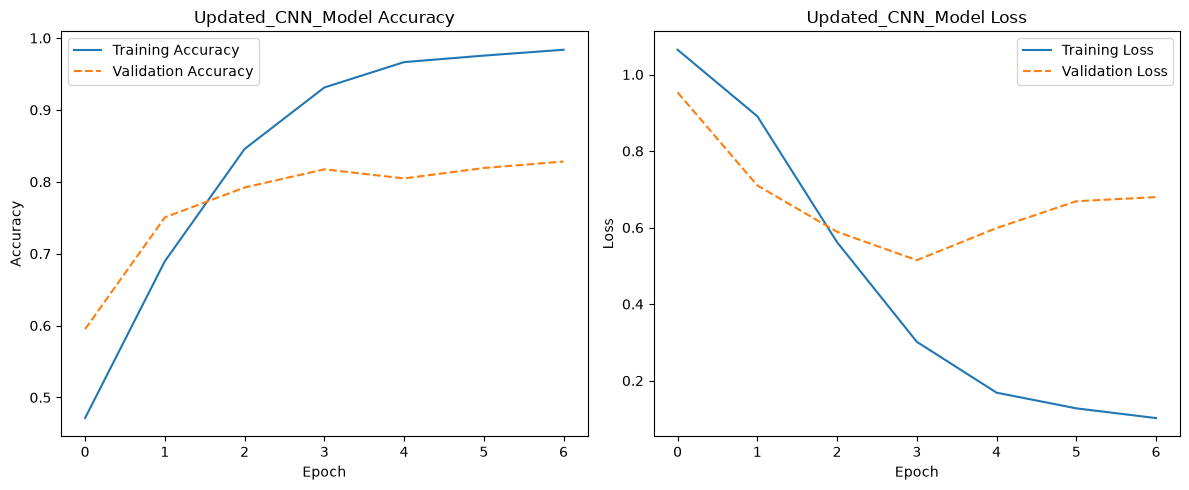

 Training history plot saved as outputs/Updated_CNN_Model_training_history.png


In [32]:
# TRAINING HISTORY VISUALISATION
plot_training_history(history_cnn, "Updated_CNN_Model")

In [33]:
# FINAL MODEL EVALUATION

# Generate predictions on the held-out test set
y_pred_probs_cnn = best_cnn_model.predict(
    X_test_pad,
    verbose=0
)

y_pred_cnn = np.argmax(
    y_pred_probs_cnn,
    axis=1
)

# Print the classification report
print("\nUpdated CNN Classification Report")

print(
    classification_report(
        y_test_encoded,
        y_pred_cnn,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        digits=4,
        zero_division=0
    )
)


Updated CNN Classification Report
              precision    recall  f1-score   support

    negative     0.6757    0.5952    0.6329        84
     neutral     0.8739    0.8881    0.8809       429
    positive     0.7403    0.7528    0.7465       178

    accuracy                         0.8177       691
   macro avg     0.7633    0.7454    0.7535       691
weighted avg     0.8154    0.8177    0.8162       691



Confusion matrix plot saved as 'outputs/Updated_CNN_Confusion_Matrix.png'


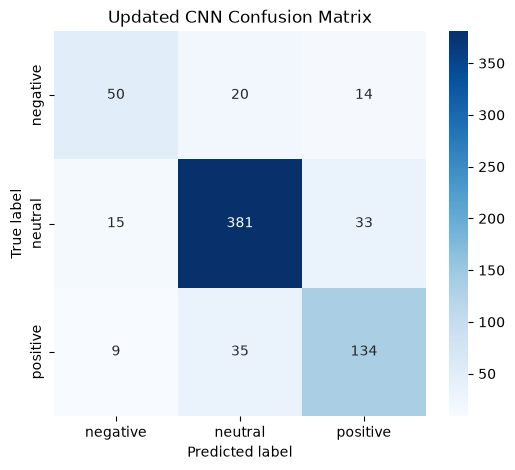

In [34]:
# CONFUSION MATRIX

cm_cnn = confusion_matrix(
    y_test_encoded,
    y_pred_cnn,
    labels=np.arange(len(label_encoder.classes_))
)

plot_confusion_matrix(
    cm_cnn,
    classes=label_encoder.classes_,
    title='Updated CNN Confusion Matrix'
)

In [35]:
# SAVE THE UPDATED CNN RESULTS

report_cnn = classification_report(
    y_test_encoded,
    y_pred_cnn,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

model_results['Updated CNN'] = {
    'f1_score_macro': report_cnn['macro avg']['f1-score'],
    'accuracy': report_cnn['accuracy'],
    'best_params': best_hps_cnn.values
}

print("\nUpdated CNN results saved to results dictionary.")


Updated CNN results saved to results dictionary.


The results from the CNN Model have been added to Logistic Regression and Multinomial Naive Bayes Models in the `model_results` dictionary.

### Bidirectional Long Short-Term Memory (Bi-LSTM)

In [36]:
# Function to build the BiLSTM 

def build_bilstm_model(hp):
    """
    This function builds and compiles a Bidirectional LSTM model for KerasTuner.
    
    Args:
        hp (kt.HyperParameters): The KerasTuner HyperParameters object.
        
    Returns:
        keras.Model: A compiled Keras model.
    """
    model = models.Sequential()
    model.add(layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, input_length=MAX_LEN))
    
    # Tune the number of units in the Bi-LSTM layer
    hp_lstm_units = hp.Int('lstm_units', min_value=32, max_value=128, step=32)
    model.add(layers.Bidirectional(layers.LSTM(units=hp_lstm_units)))
    
    # Tune the dropout rate
    hp_dropout = hp.Float('dropout', min_value=0.2, max_value=0.5, step=0.1)
    model.add(layers.Dropout(hp_dropout))
    
    model.add(layers.Dense(3, activation='softmax'))
    
    # Tune the learning rate
    hp_learning_rate = hp.Choice('learning_rate', values=[1e-3, 1e-4])
    
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=hp_learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'])
    
    return model

In [37]:
# Hyperparameter Tuning 

# Instantiate the tuner for the BiLSTM model
tuner_bilstm = kt.Hyperband(
    build_bilstm_model,
    objective='val_accuracy',
    max_epochs=10,
    factor=3,
    directory='kerastuner',
    project_name='bilstm_tuning',
    overwrite=True)

# Run the hyperparameter search
print("\n Starting Bi-LSTM Hyperparameter Search")
tuner_bilstm.search(
    X_train_pad,
    y_train_encoded,
    epochs=10,
    validation_split=0.2,
    callbacks=[early_stopping],
    class_weight=class_weight_dict)

best_hps_bilstm = tuner_bilstm.get_best_hyperparameters(num_trials=1)[0]
print(f"\n--  Bi-LSTM Tuning Complete  --\nOptimal LSTM units: {best_hps_bilstm.get('lstm_units')}\nOptimal dropout: {best_hps_bilstm.get('dropout'):.2f}\nOptimal learning rate: {best_hps_bilstm.get('learning_rate')}")

Trial 30 Complete [00h 00m 11s]
val_accuracy: 0.5497737526893616

Best val_accuracy So Far: 0.807692289352417
Total elapsed time: 00h 03m 36s

--  Bi-LSTM Tuning Complete  --
Optimal LSTM units: 128
Optimal dropout: 0.30
Optimal learning rate: 0.001


**Final Training and Evaluation**

The `build_bilstm_model` function is used to construct a new model instance populated with the best hyperparameter values found.

In [38]:
final_bilstm_model = build_bilstm_model(best_hps_bilstm)

# Train the final model to get a history object for plotting
history_bilstm = final_bilstm_model.fit(
    X_train_pad,
    y_train_encoded,
    epochs=20, 
    validation_data=(X_test_pad, y_test_encoded),
    callbacks=[early_stopping],
    class_weight=class_weight_dict)

Epoch 1/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.4803 - loss: 0.9988 - val_accuracy: 0.6122 - val_loss: 0.8567
Epoch 2/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - accuracy: 0.7569 - loss: 0.7005 - val_accuracy: 0.7323 - val_loss: 0.6748
Epoch 3/20
70/70 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - accuracy: 0.8950 - loss: 0.3405 - val_accuracy: 0.7438 - val_loss: 0.6451
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.


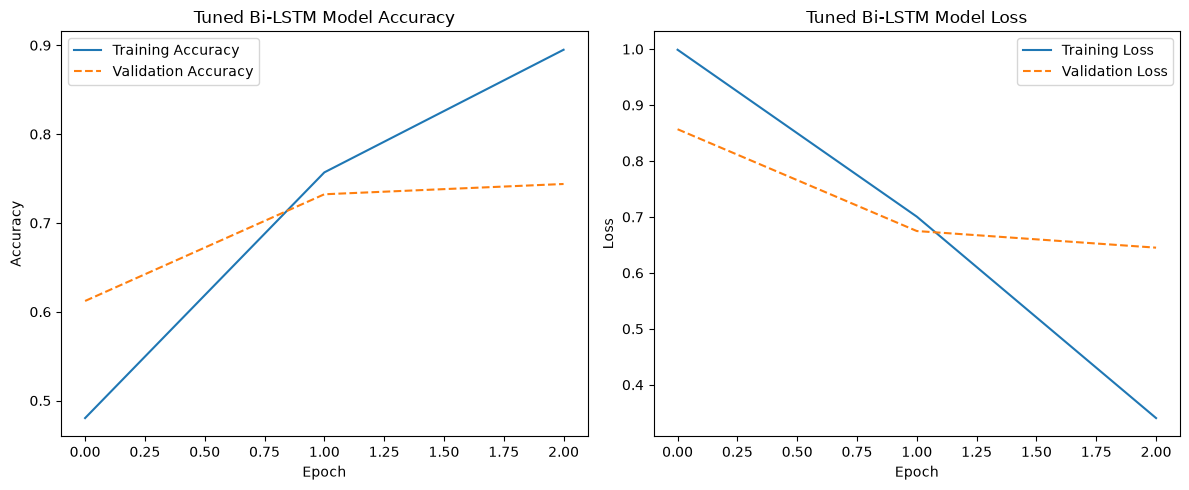

 Training history plot saved as outputs/Tuned Bi-LSTM Model_training_history.png


In [39]:
# visualise the training history
plot_training_history(history_bilstm, "Tuned Bi-LSTM Model")

In [40]:
# Final evaluation
y_pred_probs_bilstm = final_bilstm_model.predict(X_test_pad)
y_pred_bilstm = np.argmax(y_pred_probs_bilstm, axis=1)

print("\n--    Tuned Bi-LSTM Classification Report    --")
print(classification_report(y_test_encoded, y_pred_bilstm, target_names=label_encoder.classes_, digits=4))

22/22 ━━━━━━━━━━━━━━━━━━━━ 7s 332ms/step

--    Tuned Bi-LSTM Classification Report    --
              precision    recall  f1-score   support

    negative     0.2850    0.7024    0.4055        84
     neutral     0.8375    0.7809    0.8082       429
    positive     0.3452    0.1629    0.2214       178

    accuracy                         0.6122       691
   macro avg     0.4893    0.5487    0.4784       691
weighted avg     0.6435    0.6122    0.6081       691



Confusion matrix plot saved as 'outputs/Tuned_Bi-LSTM_Confusion_Matrix.png'


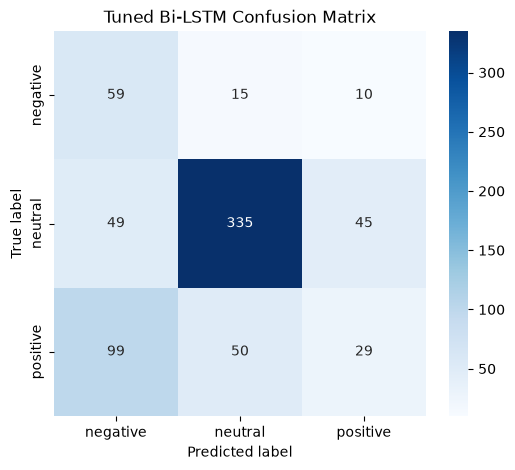

In [41]:
# Visualising the confusion matrix
cm_bilstm = confusion_matrix(y_test_encoded, y_pred_bilstm)
plot_confusion_matrix(cm_bilstm, classes=label_encoder.classes_, title='Tuned Bi-LSTM Confusion Matrix')

In [42]:
# Save the results to the model_results dictionary
report_bilstm = classification_report(y_test_encoded, y_pred_bilstm, output_dict=True)
model_results['Tuned Bi-LSTM'] = {
    'f1_score_macro': report_bilstm['macro avg']['f1-score'],
    'accuracy': report_bilstm['accuracy'],
    'best_params': best_hps_bilstm.values}

print("\nTuned Bi-LSTM results saved to dictionary.")


Tuned Bi-LSTM results saved to dictionary.


### Comparing All Models

Here the results of all the models are compared for analysis 

In [43]:
# Set pandas display options to show the 'best_params' column fully
pd.set_option('display.max_colwidth', None)

# Convert the results dictionary to a DataFrame and transpose it
results_df = pd.DataFrame(model_results).T

# Sort the DataFrame by the F1-score in descending order to rank the models
results_df = results_df.sort_values(by='f1_score_macro', ascending=False)

# Format the numerical columns for better readability
results_df['accuracy'] = (results_df['accuracy'] * 100).map('{:.2f}%'.format)
results_df['f1_score_macro'] = results_df['f1_score_macro'].map('{:.4f}'.format)

# Reorder columns for a better presentation
results_df = results_df[['accuracy', 'f1_score_macro', 'best_params']]

print("Final Model Performance Comparison:")
display(results_df)

Final Model Performance Comparison:


,accuracy,f1_score_macro,best_params
LogisticRegression,82.49%,0.7613,"{'C': 100, 'solver': 'saga'}"
Updated CNN,81.77%,0.7535,"{'filters_1': 64, 'filters_2': 16, 'dense_units': 32, 'dropout': 0.4, 'learning_rate': 0.001, 'tuner/epochs': 20, 'tuner/initial_epoch': 7, 'tuner/bracket': 2, 'tuner/round': 2, 'tuner/trial_id': '0014'}"
Tuned CNN,76.85%,0.7010,"{'filters_1': 128, 'filters_2': 32, 'dense_units': 96, 'dropout': 0.30000000000000004, 'learning_rate': 0.001, 'tuner/epochs': 10, 'tuner/initial_epoch': 4, 'tuner/bracket': 1, 'tuner/round': 1, 'tuner/trial_id': '0019'}"
MultinomialNB,75.54%,0.6788,{'alpha': 0.01}
Tuned Bi-LSTM,61.22%,0.4784,"{'lstm_units': 128, 'dropout': 0.30000000000000004, 'learning_rate': 0.001, 'tuner/epochs': 10, 'tuner/initial_epoch': 4, 'tuner/bracket': 2, 'tuner/round': 2, 'tuner/trial_id': '0013'}"


Here we see the results of all the model sorted by their F1 scores. The Logistic Regression model is ranked as the best with an accuracy of ~82% and an F1 macro score of 0.7613

#### Visual comparison

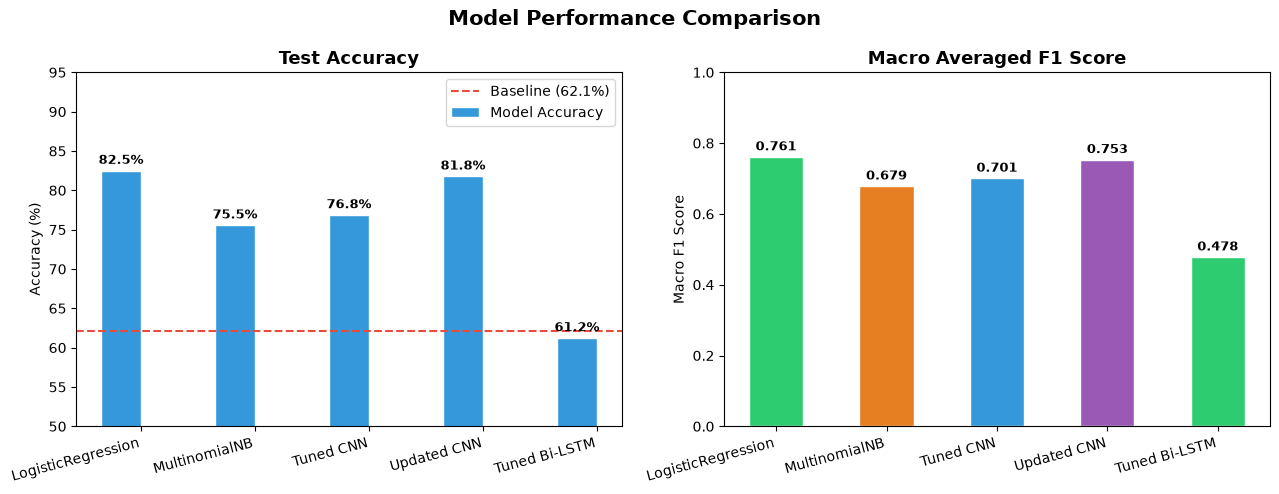

In [44]:
models_names = [k for k in model_results.keys()]
accuracies   = [model_results[k]["accuracy"] * 100 for k in models_names]
macro_f1s    = [model_results[k]["f1_score_macro"] for k in models_names]

x = np.arange(len(models_names))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Accuracy
bars1 = axes[0].bar(x - width/2, accuracies, width,
                     label="Model Accuracy", color="#3498db", edgecolor="white")
axes[0].axhline(majority_baseline, color="#e74c3c", linestyle="--", linewidth=1.5,
                label=f"Baseline ({majority_baseline:.1f}%)")
axes[0].set_xticks(x); axes[0].set_xticklabels(models_names, rotation=15, ha="right")
axes[0].set_ylim(50, 95)
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_title("Test Accuracy", fontsize=13, fontweight="bold")
axes[0].legend()
for bar, val in zip(bars1, accuracies):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f"{val:.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")

# Macro F1
bars2 = axes[1].bar(x, macro_f1s, width * 1.4,
                     color=["#2ecc71", "#e67e22", "#3498db", "#9b59b6"],
                     edgecolor="white")
axes[1].set_xticks(x); axes[1].set_xticklabels(models_names, rotation=15, ha="right")
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Macro F1 Score")
axes[1].set_title("Macro Averaged F1 Score", fontsize=13, fontweight="bold")
for bar, val in zip(bars2, macro_f1s):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f"{val:.3f}", ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.suptitle("Model Performance Comparison", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig("outputs/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


A performance comparison across all evaluated models shows that **Logistic Regression** achieved the highest overall results, leading withan accuracy of **~82.5%** and a macro F1-score of **0.761**. The **Updated CNN** closely followed with **~81.8%** accuracy and an F1-score of **~0.754**, demonstrating a significant improvement over the initial **Tuned CNN** (**76.85%** accuracy, **0.701** F1). Meanwhile, **MultinomialNB** reached **~75.5%** accuracy (**0.679** F1), and the **Tuned Bi-LSTM** underperformed relative to the others, recording the lowest metrics at **~61.2%** accuracy and an F1-score of **0.478**. All models except the Tuned Bi-LSTM successfully outperformed the majority class baseline of **62.1%**.

_The End_